In [1]:
import numpy as np
import pandas as pd
from  pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns   
import sys
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parents[1]
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_cleaning.main import clean_games_data, clean_moves_data
from src.EDA.helpers import are_there_outliers, spearman_with_target
from src.data_transforming.main import build_features_dataframe
from scipy.stats import spearmanr

/home/javier/Universidad/grupoAries/pruebasML/elo_predictor/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:


dataDirectory = Path.cwd().parents[1] / 'data'

COLUMNS_GAMES = [
    'game_id', 'result', 'white_elo',
    'black_elo', 'time_control', 'termination',
    'num_plies'
]
COLUMNS_MOVES = [
    'game_id', 'ply', 'move_number',
    'eval', 'mate', 'clock'
]

CHUNK_SIZE = 250_000

cleaned_games_chunks : list[pd.DataFrame] = []
cleaned_moves_chunks : list[pd.DataFrame] = []

for chunk in tqdm(pd.read_csv(dataDirectory / 'lichess_db_standard_rated_2018-06_games.csv', chunksize=CHUNK_SIZE), desc='Processing games data', unit='Chunk'):
    cleaned_games_chunks.append(clean_games_data(chunk))

cleaned_games_data = pd.concat(cleaned_games_chunks)

for chunk in tqdm(pd.read_csv(dataDirectory / 'lichess_db_standard_rated_2018-06_moves.csv', chunksize=CHUNK_SIZE), desc='Processing moves data', unit='Chunk'):
    cleaned_moves_chunks.append(clean_moves_data(chunk, cleaned_games_data['game_id']))

cleaned_moves_data = pd.concat(cleaned_moves_chunks)

cleaned_games_data.to_csv(PROJECT_ROOT / 'data' / 'cleaned_games.csv')
cleaned_moves_data.to_csv(PROJECT_ROOT / 'data' / 'cleaned_moves.csv')

Processing games data: 6Chunk [00:00,  7.26Chunk/s]
Processing moves data: 383Chunk [00:31, 12.05Chunk/s]


In [2]:
dataDirectory = Path.cwd().parents[1] / 'data'

cleaned_games_data = pd.read_csv(dataDirectory / 'cleaned_games.csv')
cleaned_moves_data = pd.read_csv(dataDirectory / 'cleaned_moves.csv')

In [17]:
cleaned_games_data.head()


,Unnamed: 0,game_id,result,white_elo,black_elo,time_control,termination,num_plies
0,22,QuEQ3dBV,0-1,1556,1538,600+0,Normal,66
1,29,MQHorkOO,1-0,985,1068,600+0,Normal,59
2,41,3B4avRhC,1-0,1739,1694,600+0,Normal,41
3,42,1XmaeJMU,1-0,1063,1049,600+0,Normal,51
4,54,wY1TtXW0,0-1,1505,2009,900+0,Normal,112


In [6]:
cleaned_moves_data.head(56)

,Unnamed: 0,game_id,ply,move_number,eval,mate,clock
0,1551,QuEQ3dBV,1,1,8.0,NaN,600.0
1,1552,QuEQ3dBV,2,1,13.0,NaN,600.0
2,1553,QuEQ3dBV,3,2,18.0,NaN,598.0
3,1554,QuEQ3dBV,4,2,60.0,NaN,598.0
4,1555,QuEQ3dBV,5,3,0.0,NaN,595.0
5,1556,QuEQ3dBV,6,3,10.0,NaN,587.0
6,1557,QuEQ3dBV,7,4,-17.0,NaN,592.0
7,1558,QuEQ3dBV,8,4,69.0,NaN,577.0
8,1559,QuEQ3dBV,9,5,41.0,NaN,586.0
9,1560,QuEQ3dBV,10,5,37.0,NaN,552.0


In [5]:
cleaned_games_data.shape

(263887, 7)

In [6]:
cleaned_moves_data.shape

(17486115, 6)

In [7]:
cleaned_games_data.info()

<class 'pandas.DataFrame'>
Index: 263887 entries, 22 to 1492853
Data columns (total 7 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   game_id       263887 non-null  str  
 1   result        263887 non-null  str  
 2   white_elo     263887 non-null  int64
 3   black_elo     263887 non-null  int64
 4   time_control  263887 non-null  str  
 5   termination   263887 non-null  str  
 6   num_plies     263887 non-null  int64
dtypes: int64(3), str(4)
memory usage: 22.0 MB


In [8]:
cleaned_moves_data.info()

<class 'pandas.DataFrame'>
Index: 17486115 entries, 1551 to 95708592
Data columns (total 6 columns):
 #   Column       Dtype  
---  ------       -----  
 0   game_id      str    
 1   ply          int64  
 2   move_number  int64  
 3   eval         float64
 4   mate         float64
 5   clock        float64
dtypes: float64(3), int64(2), str(1)
memory usage: 1.0 GB


In [9]:
cleaned_games_data.describe()

,white_elo,black_elo,num_plies
count,263887.000000,263887.000000,263887.000000
mean,1571.344390,1571.959850,66.263647
std,289.974445,290.255487,29.062031
min,800.000000,800.000000,11.000000
25%,1368.000000,1368.000000,46.000000
50%,1576.000000,1578.000000,61.000000
75%,1777.000000,1778.000000,81.000000
max,2665.000000,2667.000000,199.000000


In [10]:
cleaned_games_data['time_control'].value_counts(normalize=True)

time_control
600+0     0.673485
900+0     0.050965
300+5     0.029547
300+8     0.028478
600+5     0.021585
            ...   
45+11     0.000004
120+13    0.000004
480+14    0.000004
240+13    0.000004
90+35     0.000004
Name: proportion, Length: 308, dtype: float64

In [11]:
cleaned_games_data['termination'].value_counts()

termination
Normal          230711
Time forfeit     33176
Name: count, dtype: int64

In [18]:
X_games = cleaned_games_data.drop(columns=['white_elo', 'black_elo'])
y = cleaned_games_data[['white_elo', 'black_elo']] 

X_moves = cleaned_moves_data

X_train_games, X_test_games, y_train, y_test = train_test_split(X_games, y, test_size=0.2, random_state=0)

## Games data

--------------------
Name: white_elo
Type: numerical
Are there outliers?: True
% of missing values: 0.0%


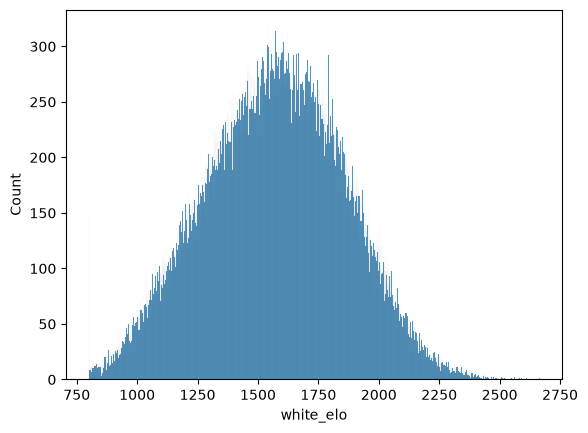

--------------------
Name: black_elo
Type: numerical
Are there outliers?: True
% of missing values: 0.0%


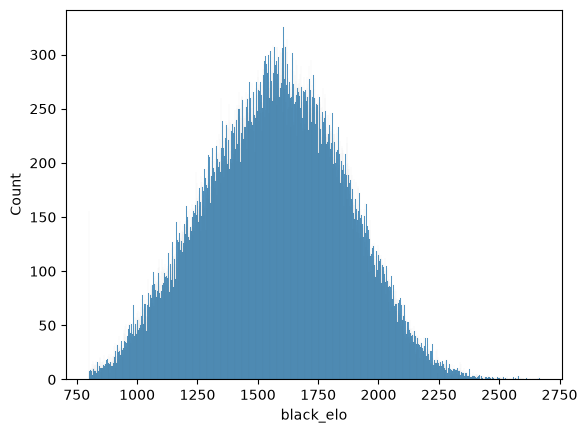

--------------------
Name: num_plies
Type: numerical
Are there outliers?: True
% of missing values: 0.0%


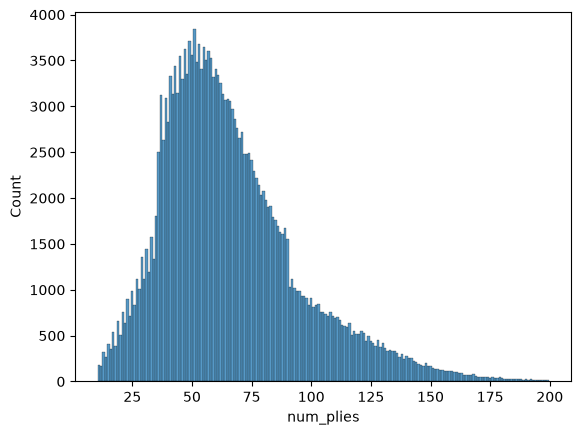

--------------------


In [19]:
NUMERICAL_COLS_TO_PLOT = ['white_elo', 'black_elo', 'num_plies']
NUMERICAL_COLS_IN_X = ['num_plies']

print("--------------------")
for col in NUMERICAL_COLS_TO_PLOT:
    print(f"Name: {col}")
    print("Type: numerical")
    print(f"Are there outliers?: {are_there_outliers(X_train_games if (col in NUMERICAL_COLS_IN_X) else y_train, col)}")
    print(f"% of missing values: {X_train_games[col].isna().mean()*100 if (col in NUMERICAL_COLS_IN_X) else y_train[col].isna().mean()*100}%")
    sns.histplot(data=X_train_games if col in NUMERICAL_COLS_IN_X else y_train, x=col, discrete=True)
    plt.show()
    print("--------------------")

rho=0.139, p=0.00e+00


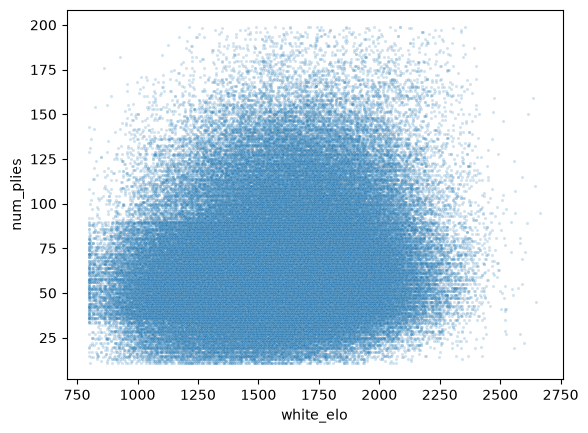

rho=0.146, p=0.00e+00


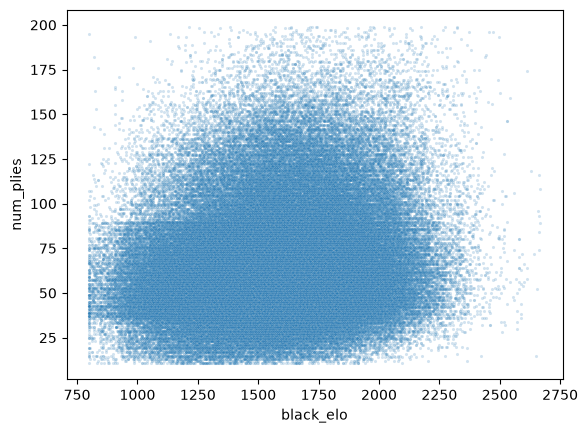

In [20]:
COLS = ['white_elo', 'black_elo']
for col in COLS:
    rho, p = spearmanr(X_train_games['num_plies'], y_train[col])
    print(f"rho={rho:.3f}, p={p:.2e}")
    sns.scatterplot(data=X_train_games, x=y_train[col], y='num_plies', alpha=0.2, s=5)
    plt.show()

    

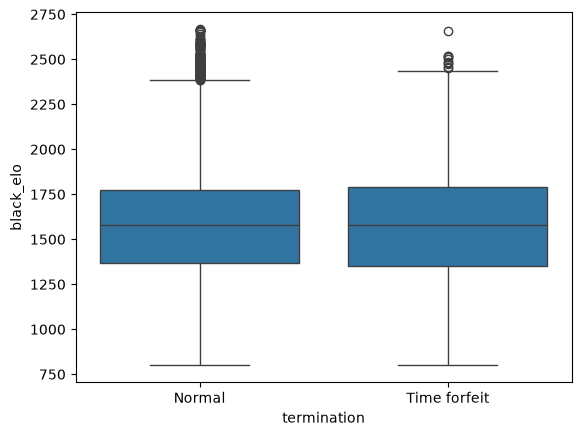

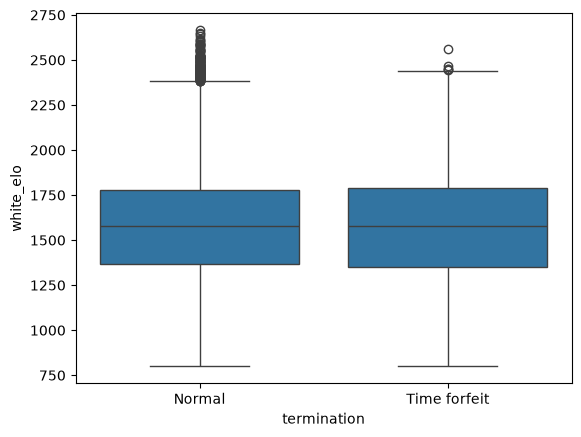

In [15]:
sns.boxplot(data=X_train_games,x = 'termination', y=y_train['black_elo'])
plt.show()

sns.boxplot(data=X_train_games,x = 'termination', y=y_train['white_elo'])
plt.show()

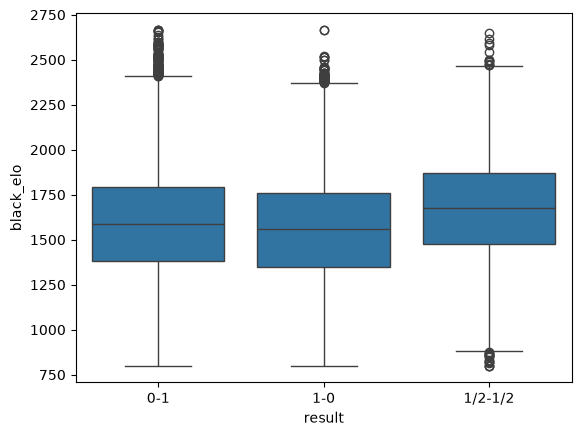

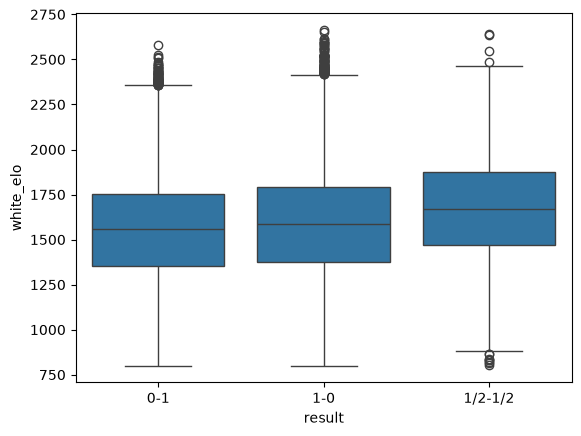

In [21]:
sns.boxplot(data=X_train_games,x = 'result', y=y_train['black_elo'])
plt.show()

sns.boxplot(data=X_train_games,x = 'result', y=y_train['white_elo'])
plt.show()

In [3]:
g = build_features_dataframe(cleaned_moves_data, cleaned_games_data)

In [4]:
g.head()

,game_id,num_plies,base_time,increment_per_move,termination_normal,termination_time,is_white,elo,result_win,result_loss,result_draw,avg_win%_loss,highest_win%_loss,num_unseen_checkmates
0,QuEQ3dBV,66,600,0,True,False,1,1556,False,True,False,4.038328,60.079315,0
1,MQHorkOO,59,600,0,True,False,1,985,True,False,False,8.663541,75.094179,0
2,3B4avRhC,41,600,0,True,False,1,1739,True,False,False,3.031279,22.480301,0
3,1XmaeJMU,51,600,0,True,False,1,1063,True,False,False,1.239211,9.048893,0
4,wY1TtXW0,112,900,0,True,False,1,1505,False,True,False,3.082308,14.986071,0


In [4]:
g.to_csv(dataDirectory / 'features.csv', index=False)

In [4]:
g.shape

(527774, 14)

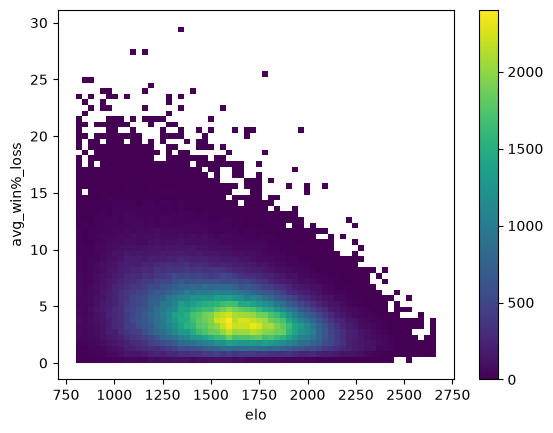

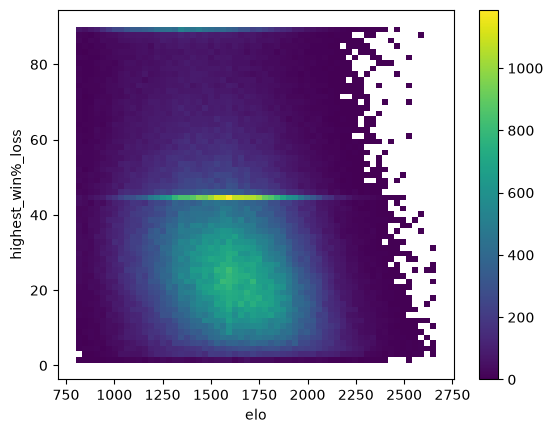

In [5]:
Y_TO_PLOT = ['avg_win%_loss', 'highest_win%_loss']

for col in Y_TO_PLOT:
    sns.histplot(data=g, x='elo', y=col, bins=60, cbar=True, cmap='viridis')
    plt.show()

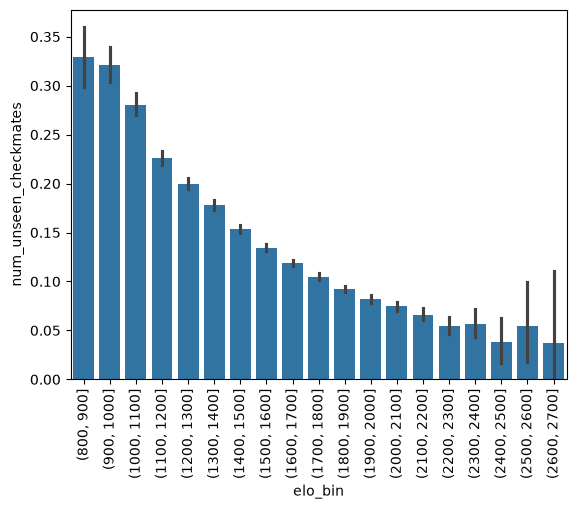

In [6]:
g['elo_bin'] = pd.cut(g['elo'], bins=range(800, 2800, 100))
sns.barplot(data=g, x='elo_bin', y='num_unseen_checkmates')
plt.xticks(rotation=90)
plt.show()

In [5]:
spearman_with_target(g, 'elo', ['avg_win%_loss', 'highest_win%_loss', 'num_plies', 'num_unseen_checkmates'])

avg_win%_loss           -0.270121
highest_win%_loss       -0.219357
num_unseen_checkmates   -0.101392
num_plies                0.141813
dtype: float64

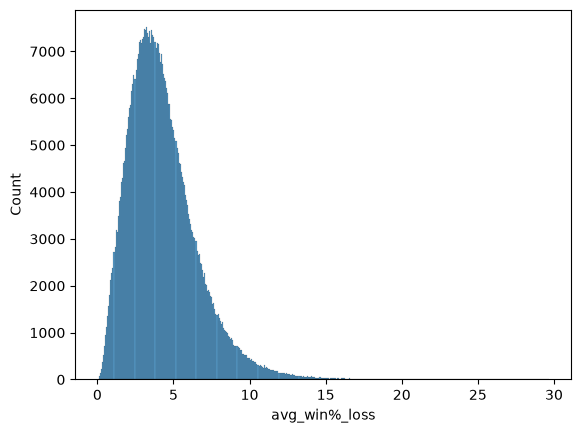

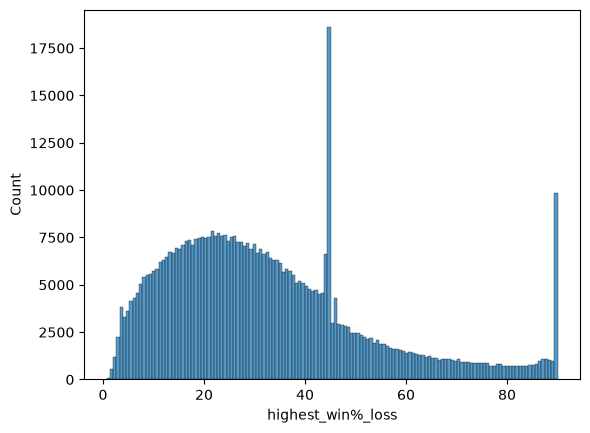

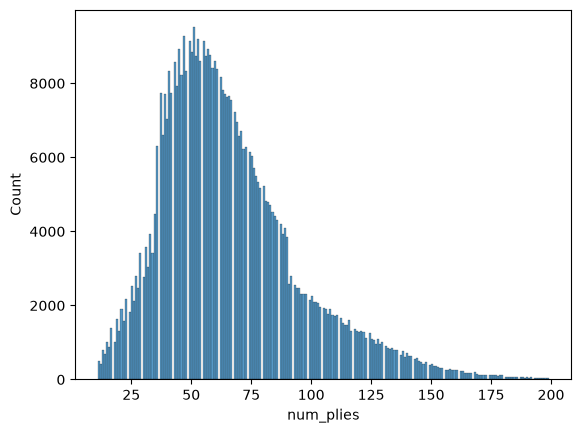

In [9]:
NUM_COLS = ['avg_win%_loss', 'highest_win%_loss', 'num_plies']
for col in NUM_COLS:
    sns.histplot(data=g, x=col)
    plt.show()